# # 06 · Positional encodings
#
# Self-attention is permutation-invariant — it needs to be *told* where tokens are. Options:
#
# * **Sinusoidal** (original Transformer): fixed sines/cosines added to the embeddings
# * **Learned absolute** (GPT-2, BERT): a trainable table — can't go beyond its size
# * **RoPE** (LLaMA, Qwen): rotate Q and K by position-dependent angles → relative information
# * **ALiBi** (BLOOM, MPT): add a distance-proportional penalty to attention scores
# * **NoPE**: nothing at all — causal masking leaks order information anyway
#
# We train all five on 64-token windows and then **test on longer contexts** (length extrapolation).

In [1]:
import math
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, pandas as pd
from llmarch import *
from llmarch.blocks import rope_cos_sin, apply_rope, RMSNorm, SwiGLU
set_seed(0); device = get_device(); STEPS = 1000; TRAIN_T = 64
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

# ## What each encoding looks like

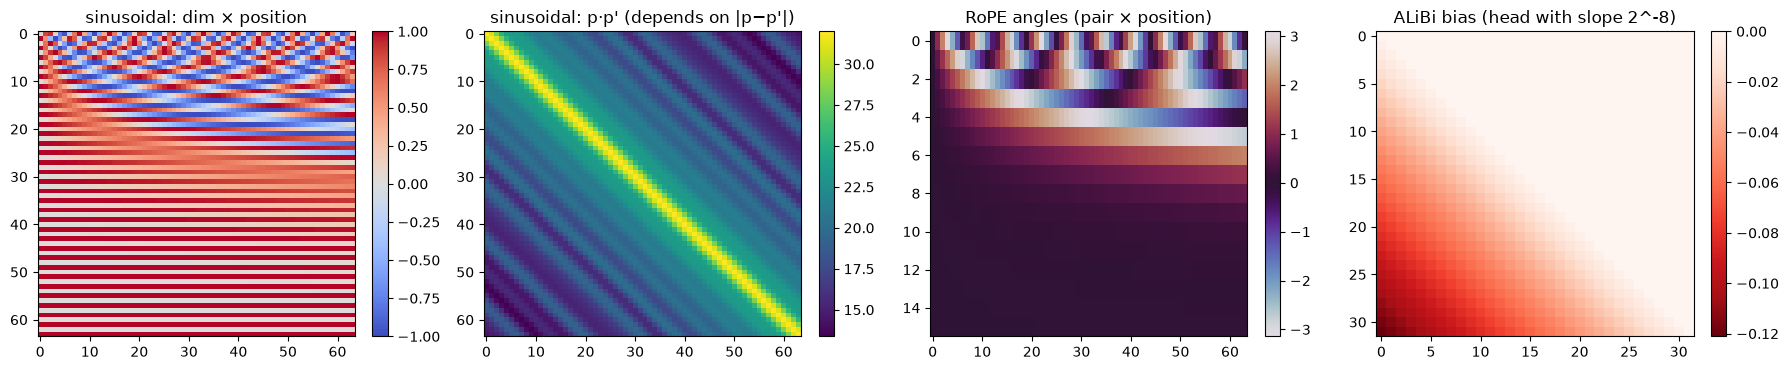

/var/folders/fp/mmfwxn_11qxcbh9nfmxgq1c80000gn/T/ipykernel_24868/671661247.py:15: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  for k, s in enumerate(alibi_slopes(8)): ax.plot(-np.arange(0, 64), -s * np.arange(0, 64), label=f"head {k}")


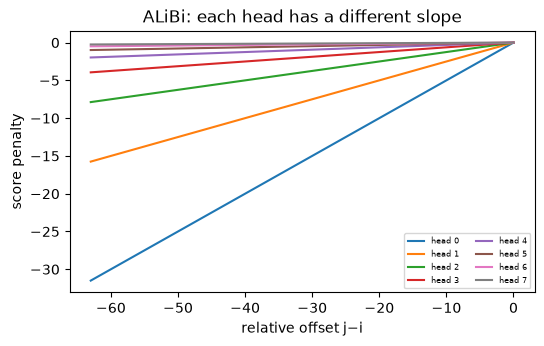

In [2]:
T, D = 64, 64
pos = torch.arange(T)[:, None]; i = torch.arange(0, D, 2)[None]
sin_pe = torch.zeros(T, D); sin_pe[:, 0::2] = torch.sin(pos / 10000 ** (i / D)); sin_pe[:, 1::2] = torch.cos(pos / 10000 ** (i / D))
def alibi_slopes(h): return torch.tensor([2 ** (-8 * (k + 1) / h) for k in range(h)])
def alibi_bias(h, T):
    dist = (torch.arange(T)[None, :] - torch.arange(T)[:, None]).clamp(max=0).float()   # j - i  (<= 0 for the past)
    return alibi_slopes(h)[:, None, None] * dist
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
plot_heatmap(sin_pe.T, title="sinusoidal: dim × position", ax=axs[0], cmap="coolwarm")
plot_heatmap(sin_pe @ sin_pe.T, title="sinusoidal: p·p' (depends on |p−p'|)", ax=axs[1])
cos, sin = rope_cos_sin(T, 32); plot_heatmap(torch.atan2(sin, cos).T, title="RoPE angles (pair × position)", ax=axs[2], cmap="twilight")
plot_heatmap(alibi_bias(4, 32)[3], title="ALiBi bias, steepest head... no: slope smallest of 4", ax=axs[3], cmap="Reds_r")
axs[3].set_title("ALiBi bias (head with slope 2^-8)"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.4))
for k, s in enumerate(alibi_slopes(8)): ax.plot(-np.arange(0, 64), -s * np.arange(0, 64), label=f"head {k}")
ax.set(xlabel="relative offset j−i", ylabel="score penalty", title="ALiBi: each head has a different slope"); ax.legend(fontsize=6, ncol=2); plt.show()

# ## One model, five encodings
# A compact decoder where `mode` decides how position enters.

In [3]:
class PosAttn(nn.Module):
    def __init__(s, d, h, mode):
        super().__init__(); s.h, s.hd, s.mode = h, d // h, mode; s.qkv = nn.Linear(d, 3 * d, bias=False); s.o = nn.Linear(d, d, bias=False)
        s.register_buffer("slopes", alibi_slopes(h))
    def forward(s, x):
        B, T, D = x.shape; q, k, v = [t.view(B, T, s.h, s.hd).transpose(1, 2) for t in s.qkv(x).chunk(3, -1)]
        if s.mode == "rope":
            c, sn = rope_cos_sin(T, s.hd, device=x.device); q, k = apply_rope(q, c, sn), apply_rope(k, c, sn)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device))
        if s.mode == "alibi":
            dist = (torch.arange(T, device=x.device)[None] - torch.arange(T, device=x.device)[:, None]).float()
            bias = (s.slopes[:, None, None] * dist).unsqueeze(0).masked_fill(~causal, float("-inf"))
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=bias)
        else:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=causal)
        return s.o(y.transpose(1, 2).reshape(B, T, D))

class PosLM(nn.Module):
    def __init__(s, V, mode, d=96, h=4, n=3):
        super().__init__(); s.mode = mode; s.tok = nn.Embedding(V, d)
        s.learned = nn.Embedding(TRAIN_T, d) if mode == "learned" else None
        s.register_buffer("sin", sin_pe_fn(512, d) if mode == "sinusoidal" else torch.zeros(1))
        s.layers = nn.ModuleList([nn.ModuleList([RMSNorm(d), PosAttn(d, h, mode), RMSNorm(d), SwiGLU(d)]) for _ in range(n)])
        s.nf = RMSNorm(d); s.head = nn.Linear(d, V, bias=False); s.head.weight = s.tok.weight
    def forward(s, idx):
        T = idx.size(1); x = s.tok(idx)
        if s.mode == "learned":
            if T > TRAIN_T: return torch.full((idx.size(0), T, s.head.out_features), float("nan"), device=idx.device)  # no embedding exists
            x = x + s.learned(torch.arange(T, device=idx.device))
        if s.mode == "sinusoidal": x = x + s.sin[:T]
        for n1, a, n2, f in s.layers: x = x + a(n1(x)); x = x + f(n2(x))
        return s.head(s.nf(x))
def sin_pe_fn(T, D):
    p = torch.arange(T)[:, None]; i = torch.arange(0, D, 2)[None]; pe = torch.zeros(T, D)
    pe[:, 0::2] = torch.sin(p / 10000 ** (i / D)); pe[:, 1::2] = torch.cos(p / 10000 ** (i / D)); return pe

# ## Train (context = 64) and test at 32 … 512 tokens

In [4]:
modes = ["nope", "sinusoidal", "learned", "rope", "alibi"]; models, hists = {}, {}
for m in modes:
    set_seed(0); models[m] = PosLM(V, m); print("==", m, f"{count_params(models[m]):,} params")
    hists[m] = train_lm(models[m], train, val, steps=STEPS, block_size=TRAIN_T, batch_size=32, lr=3e-3, device=device, eval_every=500, verbose=False)
lengths = [32, 64, 128, 256, 512]
@torch.no_grad()
def loss_at(model, T, n=8):
    model.eval(); ls = []
    for _ in range(n):
        x, y = get_batch(val, T, 8, device); lg = model(x); ls.append(F.cross_entropy(lg.reshape(-1, V), y.reshape(-1)).item())
    return float(np.mean(ls))
ext = pd.DataFrame({m: [loss_at(models[m], T) for T in lengths] for m in modes}, index=lengths); ext.index.name = "context length"; ext

== nope 338,688 params


== sinusoidal 338,688 params


== learned 344,832 params


== rope 338,688 params


== alibi 338,688 params


,nope,sinusoidal,learned,rope,alibi
context length,,,,,
32,2.251017,1.956619,2.052659,1.855400,2.030694
64,2.328947,2.011330,1.966570,1.932265,1.965624
128,2.413118,2.855863,NaN,2.200855,1.988670
256,2.451207,3.164056,NaN,3.027727,1.970442
512,2.487198,3.414188,NaN,3.527570,2.015759


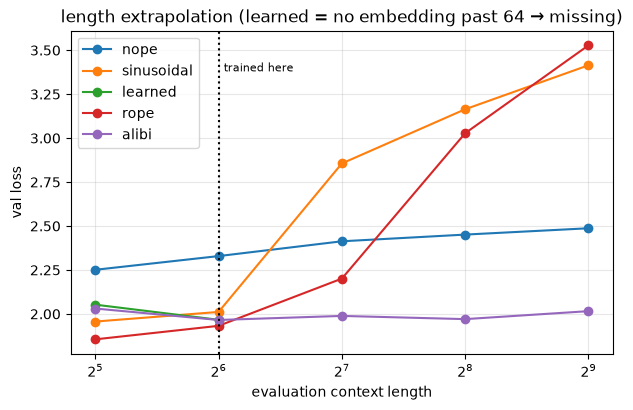

{'params': 338688,
 'val_loss': 1.821339213848114,
 'train_loss': 1.6652129292488098}

In [5]:
plt.figure(figsize=(7, 4.2))
for m in modes: plt.plot(lengths, ext[m], "o-", label=m)
plt.axvline(TRAIN_T, color="k", ls=":"); plt.text(TRAIN_T * 1.03, plt.ylim()[1] * .95, "trained here", fontsize=8, va="top")
plt.xscale("log", base=2); plt.ylim(top=min(6, plt.ylim()[1])); plt.xlabel("evaluation context length"); plt.ylabel("val loss")
plt.title("length extrapolation (learned = no embedding past 64 → missing)"); plt.legend(); plt.grid(alpha=.3); plt.show()
save_result("06 positional encoding: RoPE", models["rope"], hists["rope"])

# ## Does the model use position? Shuffle test
# If the model ignores order, shuffling the context wouldn't hurt. We compare loss on normal vs. context-shuffled windows
# (the *last* token is predicted from a shuffled prefix).

In [6]:
@torch.no_grad()
def shuffled_loss(model, T=64):
    model.eval(); x, y = get_batch(val, T, 64, device); idx = torch.randperm(T - 1); xs = torch.cat([x[:, :-1][:, idx], x[:, -1:]], 1)
    lg = model(xs)[:, -1]; return F.cross_entropy(lg, y[:, -1]).item(), F.cross_entropy(model(x)[:, -1], y[:, -1]).item()
print(pd.DataFrame({m: shuffled_loss(models[m]) for m in modes}, index=["shuffled prefix", "normal"]).round(3))

                  nope  sinusoidal  learned   rope  alibi
shuffled prefix  2.445       3.427    3.184  3.413  3.999
normal           2.396       1.693    1.954  1.676  2.274
